# Hälsostudie
**Syftet med den här studien är att undersöka mönster om en persons livstil och om det påverkar deras chanser att få sjukdom.**

In [1]:
import sys
from pathlib import Path

project_path = Path.cwd().parent

src_path = project_path / "src"

sys.path.insert(0, str(src_path))

In [2]:
import sys
from pathlib import Path

src_path = Path.cwd() / "src"

sys.path.append(str(src_path))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import ttest_ind
from studie_analyzer import HealthAnalyzer
from studie_funktioner import (
    calculate_disease_rate,
    simulate_disease_rate
)

np.random.seed(42)

In [3]:
df = pd.read_csv("../data/health_study_dataset.csv")

analyzer = HealthAnalyzer(df)

statistics = analyzer.descriptive_statistics()
display(statistics)

,age,weight,height,systolic_bp,cholesterol
mean,49.42625,73.413,171.84925,149.178625,4.92915
median,50.00000,73.200,171.35000,149.400000,4.97000
min,18.00000,33.700,144.40000,106.800000,2.50000
max,90.00000,114.400,200.40000,185.900000,7.88000


In [4]:
df.head()
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

# 1. Beskrivande Analys

In [5]:
#Räknar ut medelvärde, median, minsta tal, och största tal för dessa kategorier

kolumner = ["age", "weight", "height", "systolic_bp", "cholesterol"]

stats = df[kolumner].agg(["mean", "median", "min", "max"])

stats

,age,weight,height,systolic_bp,cholesterol
mean,49.42625,73.413,171.84925,149.178625,4.92915
median,50.00000,73.200,171.35000,149.400000,4.97000
min,18.00000,33.700,144.40000,106.800000,2.50000
max,90.00000,114.400,200.40000,185.900000,7.88000


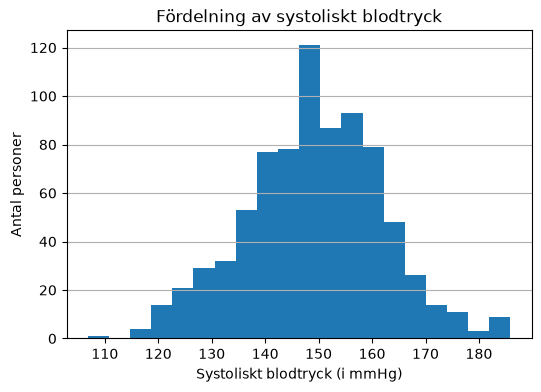

<Figure size 600x400 with 0 Axes>

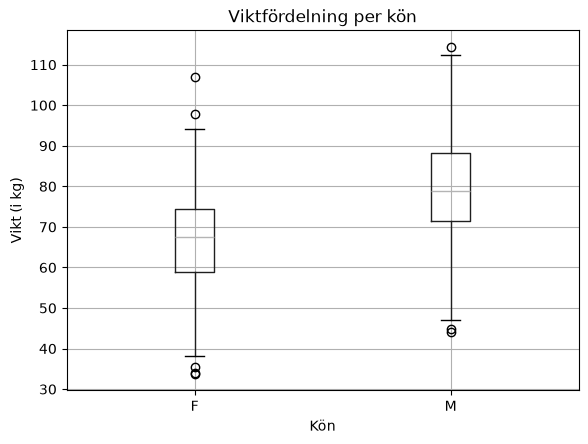

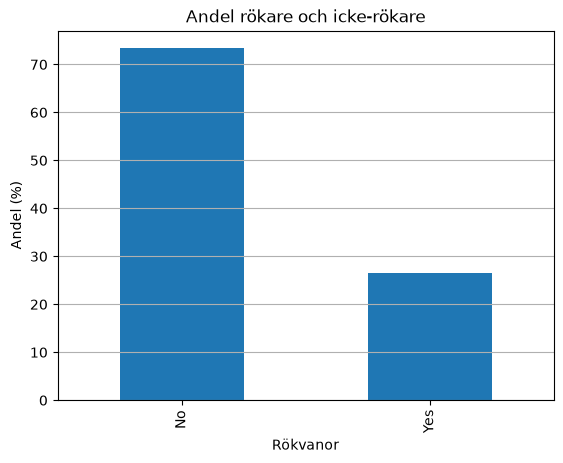

In [6]:
antal_rökare = (
    df["smoker"].value_counts(normalize=True) * 100
)

plt.figure(figsize=(6,4))
plt.hist(df["systolic_bp"], bins=20)
plt.grid(axis="y")
plt.xlabel("Systoliskt blodtryck (i mmHg)")
plt.ylabel("Antal personer")
plt.title("Fördelning av systoliskt blodtryck")
plt.show()

plt.figure(figsize=(6,4))
df.boxplot(column="weight", by="sex")
plt.xlabel("Kön")
plt.ylabel("Vikt (i kg)")
plt.title("Viktfördelning per kön")
plt.suptitle("")
plt.show()

antal_rökare.plot(kind="bar")
plt.grid(axis="y")
plt.xlabel("Rökvanor")
plt.ylabel("Andel (%)")
plt.title("Andel rökare och icke-rökare")
plt.show()

## Tolkning av datan
- Medelvärdet visar den genomsnittliga värdet för respektive variabel,
medan medianen visar det mittersta värdet i datasetet.
- Minimum och maximum visar spridningen mellan det lägsta och högsta värden för respektive variabel.

## Graferna
- Vi ser att majoriteten ligger på ungefär 150 mmHg blodtryck.
- Män har ett större median och medelvärdet än kvinnor när det kommer till vikt, men kvinnor har en större spridning.
- Över 70% av folket i studien röcker inte.

## 2. Simulerad koppling till caset
- I den här delen så undersöker vi förekomsten av sjukdomen i datan. Först räknar vi hur många människor har sjukdomen, sen simulerar vi 1000 personer med samma chans för sjukdomen, sen jämföra.

In [7]:
# Beräknar hur många personer har sjukdomen i procent

sjukdom_chans = df["disease"].mean()

print(f"Antal människor med sjukdomen: {sjukdom_chans:.2%}")

Antal människor med sjukdomen: 5.88%


In [8]:
# Simulation av 1000 personer

simulation = np.random.binomial(
    n=1,
    p=sjukdom_chans,
    size=1000
)

simulerad_chans = simulation.mean()

print(f"Simulerad mängd av folk med sjukdomen i en sample size på 1000: {simulerad_chans:.2%}")

Simulerad mängd av folk med sjukdomen i en sample size på 1000: 5.60%


In [9]:
# Jämförelse

skillnad = abs(sjukdom_chans - simulerad_chans)

print(f"Verklig andel: {sjukdom_chans:.2%}")
print(f"Simulerad andel: {simulerad_chans:.2%}")
print(f"Skillnad: {skillnad:.2%}")

Verklig andel: 5.88%
Simulerad andel: 5.60%
Skillnad: 0.27%


## Observationer av datan
- Den verkliga chansen för sjukdomen är bara 5.88% i datasetet, vilken är ungefär 47 personer.
- I simulationen med en ökning till 1000 personer istället för 800 har siffran gått ner till 5.60%, och det tillsvarar 56 personer.
- Skillnaden är liten. Men även fast simulationen har ett lägre procent så är mer personer påverkade.

In [10]:
# Med HealthAnalyzer

real_rate = calculate_disease_rate(df)
simulated_rate = simulate_disease_rate(df)

print("Verklig andel:", real_rate)
print("Simulerad andel:", simulated_rate)

Verklig andel: 0.05875
Simulerad andel: 0.054


## 3. Konfidensintervall

In [11]:
bp = df["systolic_bp"].dropna()

mean_bp = bp.mean()
std_bp = bp.std()
n = len(bp)

se = std_bp / np.sqrt(n)

fm = 1.96 * se # fm = felmarginal

lo = mean_bp - fm
hi = mean_bp + fm

print(f"Medelvärde: {mean_bp:.2f} mmHg")
print(f"95% CI: [{lo:.2f} - {hi:.2f}] mmHg")

Medelvärde: 149.18 mmHg
95% CI: [148.29 - 150.07] mmHg


## Tolknig av resultatet
- Intervallet visar osäkerheten av populationens genomsnittliga systoliska blodtryck.
- Ett litet intervall betyder den är mer litbar, medan en större intervall blir mer osäkert. I det här fallet är intervallet 1,78.

## 4. Hypotesprövning
- H₀ = Rökare har inte högre medel-blodtryck än icke-rökare.
- H₁ = Rökare har högre medel-blodtryck än icke-rökare.
- Signifikansnivå: 0.05, dvs 5% är gränsen för statistisk signifikans.

In [12]:
rökare = df.loc[df["smoker"] == "Yes", "systolic_bp"].dropna()

icke_rökare = df.loc[df["smoker"] == "No", "systolic_bp"].dropna()

print("Medel-blodtryck för rökare:", rökare.mean())
print("Medel-blodtryck för icke-rökare:", icke_rökare.mean())

Medel-blodtryck för rökare: 149.524882629108
Medel-blodtryck för icke-rökare: 149.05298126064736


In [13]:
t_statistic, p_value = ttest_ind(
    rökare,
    icke_rökare,
    equal_var=False,
    alternative="greater"
)

print(f"T-statistik: {t_statistic:.4f}")
print(f"P-värde: {p_value:.4f}")

T-statistik: 0.4503
P-värde: 0.3264


In [14]:
alpha = 0.05

if p_value < alpha:
    print("Resultatet har statistisk signifikans.")
else:
    print("Resultatet har ingen statistisk signifikans.")            

Resultatet har ingen statistisk signifikans.


## Tolkning
- Genom ett Welch t-test så undersöker vi om rökare har ett högre medel-blodtryck än dem som inte röker.
- Signifikansnivån sats till 0,05, och P-värdet jämfördes med den för att se om resultatet var statistiskt signifikant.
- P-värdet är mycket högre än 0,05, så det finns ingen statistisk signifikans.

## -- Del 2 --

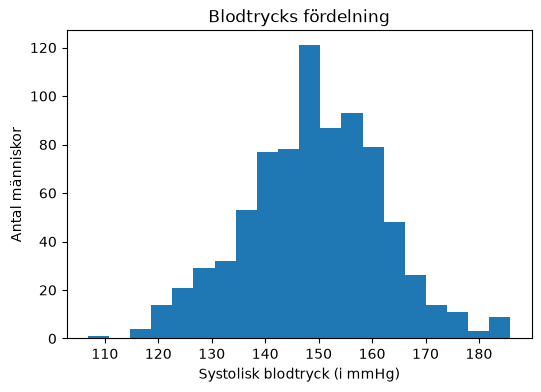

In [15]:
# Blodtrycks fördelning graf med HealthAnalyzer

analyzer.plot_bp()

In [16]:
# Regressions resultat

results = analyzer.regression_results()

for key, value in results.items():
    print(f"{key}: {value:.3f}")

Lutning: 0.536
Intercept: 122.685
R2: 0.369


- Lutningen är hur mycket blodtrycket förändras i genomsnitt per extra år (i mmHg).
- Intercept är modellens uppskattade blodtryck vid 0 år.
- R2 är hur stor del av blodtrycks variationen som modellen förklarar (ungefär 37% här).

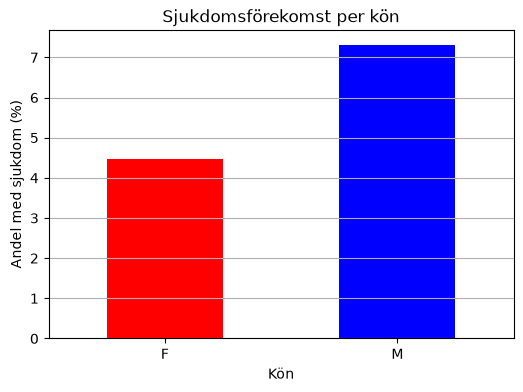

In [17]:
# Sjukdomsförekomst per kön

sjukdom_per_kön = df.groupby("sex")["disease"].mean() * 100

sjukdom_per_kön.plot(
    kind="bar",
    figsize=(6,4),
    color=["red", "blue"]
)

plt.title("Sjukdomsförekomst per kön")
plt.xlabel("Kön")
plt.ylabel("Andel med sjukdom (%)")
plt.grid(axis="y")
plt.xticks(rotation=0)
plt.show()

**Vi ser direkt att män har en större chans för sjukdomen. Bara ungefär 4.5% av kvinnor har sjukdomen, medan det är över 7%  för män.**